# 10. 장비 그룹 교차검증

기존 개발 장비 01~06 계열 12대를 4개 외부 Fold로 분리했습니다. 09/10 기존 평가 장비를 튜닝에 재사용하지 않았습니다. 각 Fold에서 5대 학습, 2대 Early Stopping, 2대 임계값 보정, 3대 외부 평가입니다. 과거 시간 분할 실험과 자료가 겹치는 후향적 분석이므로 새로운 독립 평가라고 부르지 않습니다.

재실행: `python -m src.group_validation45 --pilot` 후 `python scripts/run_improvement45.py`. 완료 실험은 재사용하고 새 설정은 새 경로에 저장해야 합니다.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import pandas as pd
from IPython.display import display,Markdown,Image
from src.improvement_common import OUT,read_json,configs
pd.set_option("display.max_columns",30)
print("실행 Python:",sys.executable)
print("저장된 실제 실험 결과를 읽습니다. 이 Notebook은 모델을 재학습하지 않습니다.")
def show(name):display(Image(filename=str(OUT/"figures"/(name+".png"))))


실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
저장된 실제 실험 결과를 읽습니다. 이 Notebook은 모델을 재학습하지 않습니다.


In [2]:
plans=read_json(OUT/"fold_plan.json");display(pd.DataFrame(plans))
counts=pd.concat([pd.DataFrame(read_json(OUT/f"fold_{i}_counts.json")).assign(fold=i) for i in range(4)])
display(counts.groupby(["fold","role"])[["rows","positive","negative","unknown","f1","f2","f3"]].sum())
for p in plans:
    sets=[set(p[k]) for k in ["train","early_stop","calibration","evaluation"]]
    assert sum(map(len,sets))==len(set.union(*sets))==12
display(pd.DataFrame({"구성":configs().keys(),"특징 수":[len(x) for x in configs().values()]}))
display(configs())

,fold,evaluation,early_stop,calibration,train
0,0,"[01M01, 03M01, 05M01]","[01M02, 02M01]","[02M02, 03M02]","[04M01, 04M02, 05M02, 06M01, 06M02]"
1,1,"[01M02, 03M02, 05M02]","[02M02, 03M01]","[04M01, 04M02]","[05M01, 06M01, 06M02, 01M01, 02M01]"
2,2,"[02M01, 04M01, 06M01]","[03M02, 04M02]","[05M01, 05M02]","[06M02, 01M01, 01M02, 02M02, 03M01]"
3,3,"[02M02, 04M02, 06M02]","[05M01, 05M02]","[06M01, 01M01]","[01M02, 02M01, 03M01, 03M02, 04M01]"


rows  positive  negative  unknown  f1  f2  f3
fold role                                                        
0    calibration  199039       276     22821   175942  25  10   2
     early_stop   380934       580    214862   165492  46   8  12
     evaluation   262809       133     36532   226144   8   7   2
     train        752794       552    193206   559036  29   5  27
1    calibration  353713       232       929   352552  16   1   9
     early_stop   168411       118         0   168293   5   9   0
     evaluation   425267       793    196650   227824  68  13  14
     train        648185       398    269842   377945  19   7  20
2    calibration  111641        32     13482    98127   2   1   1
     early_stop   361019       455     22821   337743  39   7  10
     evaluation   286787        76     57971   228740   6   4   1
     train        836129       978    373147   462004  61  18  31
3    calibration  180121        33     39059   141029   2   1   1
     early_stop   111641        32     13482    98127   2   1   1
     evaluation   620713       539    176268   443906  26   6  26
     train        683101       937    238612   443552  78  22  15

,구성,특징 수
0,A,8
1,B,80
2,C,83


{'A': ['recipe',
  'stage',
  'FLOWCOOLPRESSURE__current',
  'FLOWCOOLFLOWRATE__current',
  'IONGAUGEPRESSURE__current',
  'ETCHBEAMCURRENT__current',
  'ETCHBEAMVOLTAGE__current',
  'ETCHSUPPRESSORCURRENT__current'],
 'B': ['recipe',
  'stage',
  'FLOWCOOLPRESSURE__current',
  'FLOWCOOLPRESSURE__mean_60raw',
  'FLOWCOOLPRESSURE__std_60raw',
  'FLOWCOOLPRESSURE__min_60raw',
  'FLOWCOOLPRESSURE__max_60raw',
  'FLOWCOOLPRESSURE__delta_mean_60raw',
  'FLOWCOOLPRESSURE__rate_mean_60raw',
  'FLOWCOOLPRESSURE__mean_300raw',
  'FLOWCOOLPRESSURE__std_300raw',
  'FLOWCOOLPRESSURE__min_300raw',
  'FLOWCOOLPRESSURE__max_300raw',
  'FLOWCOOLPRESSURE__delta_mean_300raw',
  'FLOWCOOLPRESSURE__rate_mean_300raw',
  'FLOWCOOLFLOWRATE__current',
  'FLOWCOOLFLOWRATE__mean_60raw',
  'FLOWCOOLFLOWRATE__std_60raw',
  'FLOWCOOLFLOWRATE__min_60raw',
  'FLOWCOOLFLOWRATE__max_60raw',
  'FLOWCOOLFLOWRATE__delta_mean_60raw',
  'FLOWCOOLFLOWRATE__rate_mean_60raw',
  'FLOWCOOLFLOWRATE__mean_300raw',
  'FLOWCOOLFLOW

입력은 현재/과거 센서·공정 상태만 허용했습니다. TTF, 정답, next_event, Tool, time, Lot, 사용량은 입력에서 제외됩니다. 장비가 분리되어 동일 이벤트나 중첩 과거 윈도가 역할을 넘지 않습니다. 대치·스케일링은 수행하지 않았습니다.

,model,policy,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_ap_mean,pr_auc_ap_std,event_recall_mean,event_recall_std,false_alarms_per_active_hour_mean,false_alarms_per_active_hour_std,lead_time_median_raw_mean,lead_time_median_raw_std
0,A,event_far,0.084000,0.143763,0.065171,0.127001,0.003465,0.004674,0.012257,0.014817,0.078793,0.143893,0.799327,1.596704,386.000000,93.338095
1,A,f1,0.002470,0.003556,0.220475,0.269994,0.004880,0.007015,0.012257,0.014817,0.267183,0.342236,1.487565,1.750742,475.500000,33.234019
2,B,event_far,0.029001,0.038678,0.023621,0.037885,0.017228,0.032501,0.009328,0.007101,0.088390,0.140331,0.143208,0.193910,72.500000,0.707107
3,B,f1,0.016923,0.026312,0.317794,0.458401,0.021925,0.029437,0.009328,0.007101,0.407010,0.373380,1.617664,2.570927,216.750000,234.994149
4,C,event_far,0.029294,0.038264,0.023621,0.037885,0.017457,0.032370,0.009492,0.007465,0.088390,0.140331,0.142571,0.192740,72.500000,0.707107
5,C,f1,0.017147,0.026414,0.294297,0.472378,0.022202,0.029970,0.009492,0.007465,0.354871,0.413725,1.539215,2.618728,253.666667,273.233112
6,C_regularized,event_far,0.025934,0.032782,0.091456,0.105623,0.020770,0.038009,0.005864,0.005250,0.174613,0.222051,0.756848,1.326254,239.000000,147.078210
7,C_regularized,f1,0.010503,0.017079,0.381875,0.412294,0.018097,0.028410,0.005864,0.005250,0.457137,0.349413,2.993185,1.987291,350.250000,175.613923


,fold,model,policy,precision,recall,f1,pr_auc_ap,event_recall,false_alarms_per_active_hour
0,0,A,f1,0.002338,0.330827,0.004644,0.002930,0.352941,3.398333
1,0,A,event_far,0.002001,0.255639,0.003971,0.002930,0.294118,3.194382
2,0,B,f1,0.005467,0.165414,0.010585,0.006883,0.294118,0.701082
3,0,B,event_far,0.001652,0.015038,0.002976,0.006883,0.058824,0.410451
4,0,C,f1,0.009187,0.097744,0.016796,0.007593,0.176471,0.517526
5,0,C,event_far,0.002237,0.015038,0.003895,0.007593,0.058824,0.407902
6,0,C_regularized,f1,0.002461,0.180451,0.004856,0.003602,0.235294,2.661560
7,0,C_regularized,event_far,0.002754,0.180451,0.005425,0.003602,0.235294,2.735493
8,1,A,f1,0.007540,0.551072,0.014877,0.011668,0.715789,2.549121
9,1,A,event_far,0.250000,0.005044,0.009889,0.011668,0.021053,0.002577


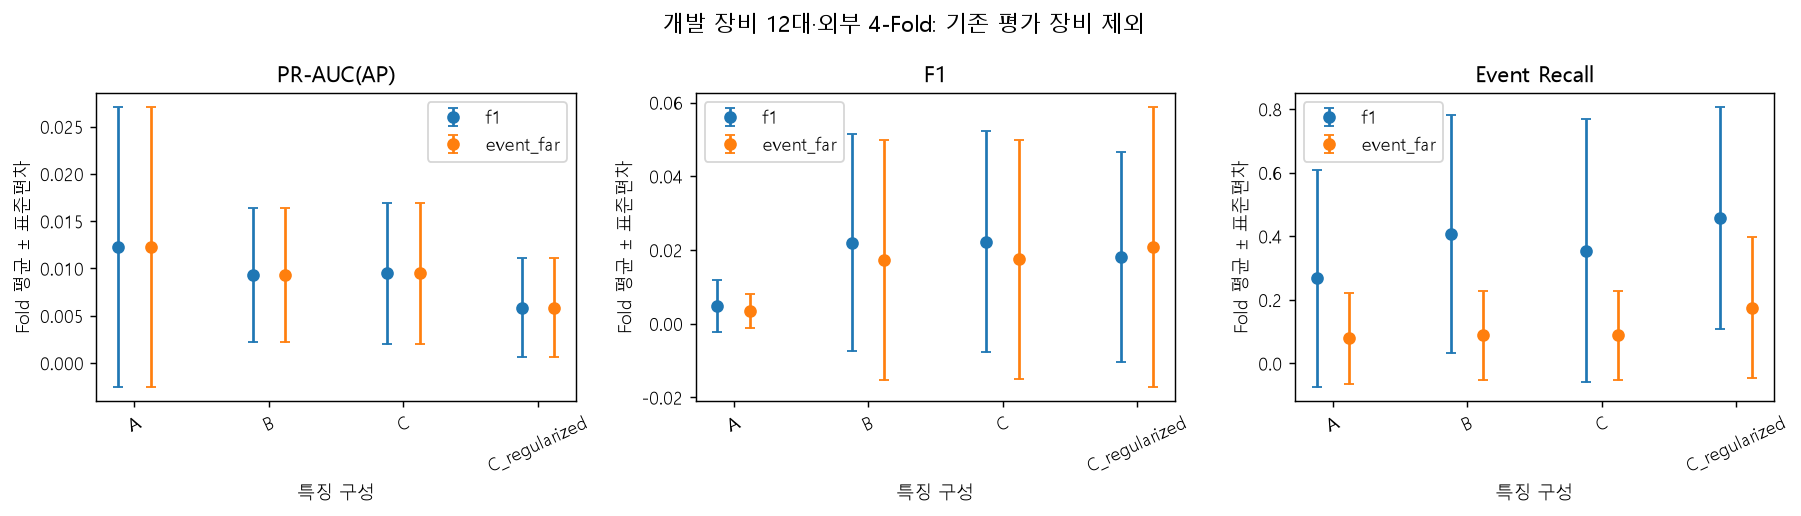

,fold,model,train_ap,pr_auc_ap,fit_seconds,peak_rss_gib,best_iteration
0,0,A,0.434004,0.002930,0.635340,1.928596,73
2,0,B,0.481068,0.006883,1.384812,1.769299,31
4,0,C,0.481329,0.007593,1.273136,1.762260,31
6,0,C_regularized,0.643726,0.003602,1.895372,1.772686,206
8,1,A,0.009549,0.011668,0.491748,1.898914,0
10,1,B,0.016685,0.019870,1.080609,1.644730,0
12,1,C,0.016685,0.019870,1.261189,1.642265,0
14,1,C_regularized,0.009500,0.013235,1.295359,1.651333,0
16,2,A,0.140885,0.001057,0.724002,2.029377,44
18,2,B,0.086073,0.004441,1.687143,1.808037,18


In [3]:
metrics=pd.read_parquet(OUT/"cv_metrics.parquet")
display(pd.read_parquet(OUT/"cv_summary.parquet"))
display(metrics[["fold","model","policy","precision","recall","f1","pr_auc_ap","event_recall","false_alarms_per_active_hour"]])
show("cv_comparison")
display(metrics[metrics.policy=="f1"][["fold","model","train_ap","pr_auc_ap","fit_seconds","peak_rss_gib","best_iteration"]])

특징을 늘려도 성능은 일관되게 좋아지지 않습니다. A의 평균 AP와 B/C의 F1·이벤트 탐지를 분리해서 해석해야 합니다. 정규화 강화 C도 외부 장비 성능을 보장하지 못했습니다. 학습 AP와 평가 AP 차이, 클래스 분포와 장비 분포의 결합은 과적합·분포 이동 가능성을 보여주지만 하나의 원인으로 확정할 수 없습니다.

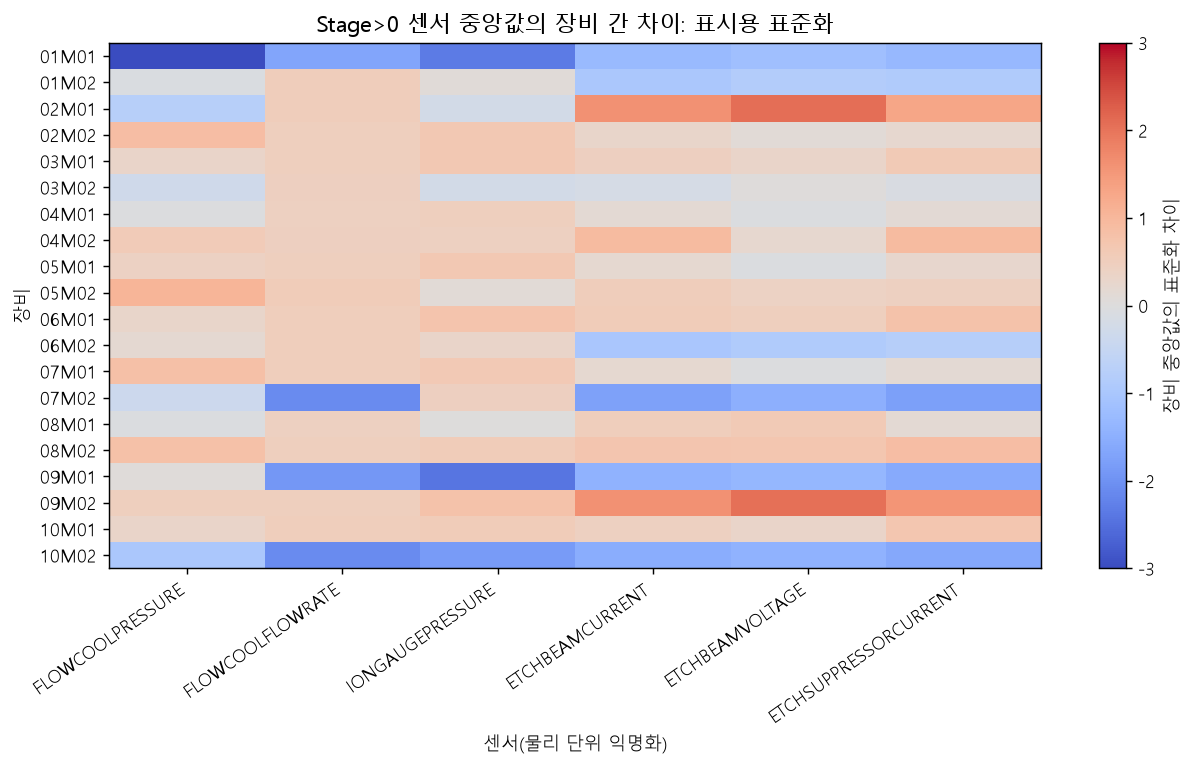

,Tool,state,rows,positive,negative,unknown,FLOWCOOLPRESSURE__current_median,FLOWCOOLFLOWRATE__current_median,IONGAUGEPRESSURE__current_median,ETCHBEAMCURRENT__current_median,ETCHBEAMVOLTAGE__current_median,ETCHSUPPRESSORCURRENT__current_median,recipe_nunique
0,01M01,Stage=0,26010,10,8902,17098,0.370294,0.686631,0.818969,1.076367,1.085495,0.964597,2
1,01M01,Stage>0,69803,13,16701,53089,-0.714114,-1.448092,-1.324002,-1.151571,-1.128402,-1.145790,36
2,01M02,Stage>0,284516,537,171276,112703,0.210171,0.562459,0.007607,-0.958304,-0.943743,-0.870962,12
3,02M01,Stage>0,96418,43,43586,52789,0.031975,0.575655,-0.156544,0.730699,0.698392,0.456930,28
4,02M02,Stage=0,5695,0,0,5695,0.475060,0.525692,0.665087,0.939111,0.908382,0.882768,1
5,02M02,Stage>0,79977,30,0,79947,0.456641,0.524689,0.317977,-0.127414,-0.403585,-0.201397,51
6,03M01,Stage=0,16953,0,0,16953,0.345715,0.538011,0.828316,1.093261,1.113393,0.927772,2
7,03M01,Stage>0,65786,88,0,65698,0.314188,0.536163,0.324691,-0.026913,-0.286457,0.016435,35
8,03M02,Stage=0,9594,21,5464,4109,0.173960,0.529648,0.777926,1.304656,1.497027,1.039543,2
9,03M02,Stage>0,103773,225,17357,86191,0.151568,0.503728,-0.150702,-0.444199,-0.447964,-0.405290,36


positive_median  negative_median  \
fault_code sensor                                                             
f1         ETCHBEAMCURRENT__current               0.137112        -0.193728   
           ETCHBEAMVOLTAGE__current              -0.059168        -0.403663   
           ETCHSUPPRESSORCURRENT__current         0.314133        -0.096383   
           FLOWCOOLFLOWRATE__current              0.518653         0.523826   
           FLOWCOOLPRESSURE__current              0.209779         0.328565   
           IONGAUGEPRESSURE__current              0.254052         0.282378   
f2         ETCHBEAMCURRENT__current              -1.272459        -0.192360   
           ETCHBEAMVOLTAGE__current              -1.240236        -0.446318   
           ETCHSUPPRESSORCURRENT__current        -1.192840        -0.085483   
           FLOWCOOLFLOWRATE__current             -0.865820         0.521856   
           FLOWCOOLPRESSURE__current              0.446738         0.293032   
           IONGAUGEPRESSURE__current             -0.663174         0.358512   
f3         ETCHBEAMCURRENT__current              -0.410130        -1.001758   
           ETCHBEAMVOLTAGE__current              -0.616250        -0.955061   
           ETCHSUPPRESSORCURRENT__current        -0.419604        -0.803954   
           FLOWCOOLFLOWRATE__current             -0.479822         0.507131   
           FLOWCOOLPRESSURE__current             -0.520296         0.243673   
           IONGAUGEPRESSURE__current             -0.112571         0.196652   

                                           median_difference_over_negative_iqr  
fault_code sensor                                                               
f1         ETCHBEAMCURRENT__current                                   0.000636  
           ETCHBEAMVOLTAGE__current                                   0.000034  
           ETCHSUPPRESSORCURRENT__current                             0.014182  
           FLOWCOOLFLOWRATE__current                                  0.000208  
           FLOWCOOLPRESSURE__current                                 -0.063985  
           IONGAUGEPRESSURE__current                                 -0.000906  
f2         ETCHBEAMCURRENT__current                                  -0.192364  
           ETCHBEAMVOLTAGE__current                                  -0.217391  
           ETCHSUPPRESSORCURRENT__current                            -0.321532  
           FLOWCOOLFLOWRATE__current                                 -0.012364  
           FLOWCOOLPRESSURE__current                                  0.122761  
           IONGAUGEPRESSURE__current                                  0.001746  
f3         ETCHBEAMCURRENT__current                                   0.001372  
           ETCHBEAMVOLTAGE__current                                  -0.004406  
           ETCHSUPPRESSORCURRENT__current                            -0.020449  
           FLOWCOOLFLOWRATE__current                                 -0.002882  
           FLOWCOOLPRESSURE__current                                 -0.484003  
           IONGAUGEPRESSURE__current                                 -0.419312

eligible  detected
model         policy    fault_code                    
A             event_far f1               108         4
                        f2                30         1
                        f3                43         2
              f1        f1               108        56
                        f2                30         4
                        f3                43        14
B             event_far f1               108        20
                        f2                30         2
                        f3                43         7
              f1        f1               108        47
                        f2                30         8
                        f3                43        34
C             event_far f1               108        20
                        f2                30         2
                        f3                43         7
              f1        f1               108        45
                        f2                30         8
                        f3                43        33
C_regularized event_far f1               108        34
                        f2                30         4
                        f3                43        10
              f1        f1               108        59
                        f2                30         9
                        f3                43        37

In [4]:
show("tool_shift")
display(pd.read_parquet(OUT/"tool_state_distribution.parquet"))
contrasts=pd.read_parquet(OUT/"fault_sensor_contrasts.parquet")
display(contrasts.groupby(["fault_code","sensor"])[["positive_median","negative_median","median_difference_over_negative_iqr"]].median())
display(pd.read_parquet(OUT/"cv_fault_metrics.parquet").groupby(["model","policy","fault_code"])[["eligible","detected"]].sum())

센서 비교는 유형별 기술 통계이며 장비·Recipe·Stage 교란을 제거한 고장 원인 분석은 아닙니다. Stage=0에서도 고장이 있어 제외하지 않았습니다. 기존 시간 분할 A/C의 순위 역전은 검증과 평가 분포가 다른 상황에서 관찰되었으며, 평가 결과를 보고 C 대신 A를 선택하면 선택 편향이 생깁니다. 이번에는 모든 사전 지정 구성을 보고합니다.